# 1. Overview

MyFinSight is a Python-based personal finance application that enables users to record and manage income and expenses, monitor their overall financial activities, and visualize spending patterns through a dashboard to support informed financial decision-making..

# 2. Objectives

- Develop a web application for recording and managing financial transactions.

- Store transaction data in a relational SQLite database.

- Categorize transactions by type, category, and account.

- Calculate financial summaries, including income, expenses, and net balance.

- Analyze spending patterns using Python and data visualizations.

# 3. Methodology

The application uses Flask for the web interface and backend logic, SQLite for data storage, and HTML, CSS, and JavaScript for user interaction. Transaction records are validated before insertion into the database.

Pandas and Matplotlib will be used to analyze recorded transactions and visualize financial patterns.

# 4. Initial Development

The initial development phase focused on implementing the core functionalities of a personal finance management application using Python, Flask, and SQLite.

The following features have been implemented:

## 4.1 Database Implementation

A relational SQLite database was created to store financial information. The database contains three related tables: accounts, categories, and transactions.

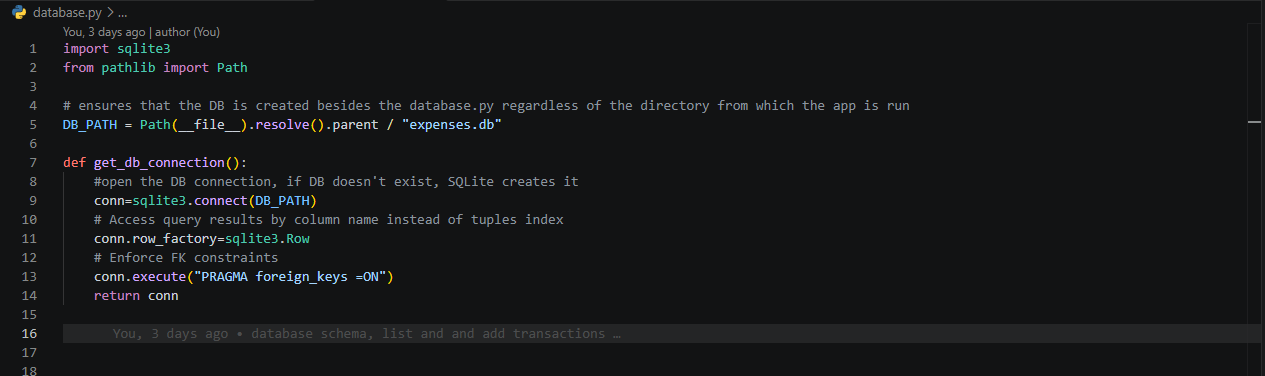

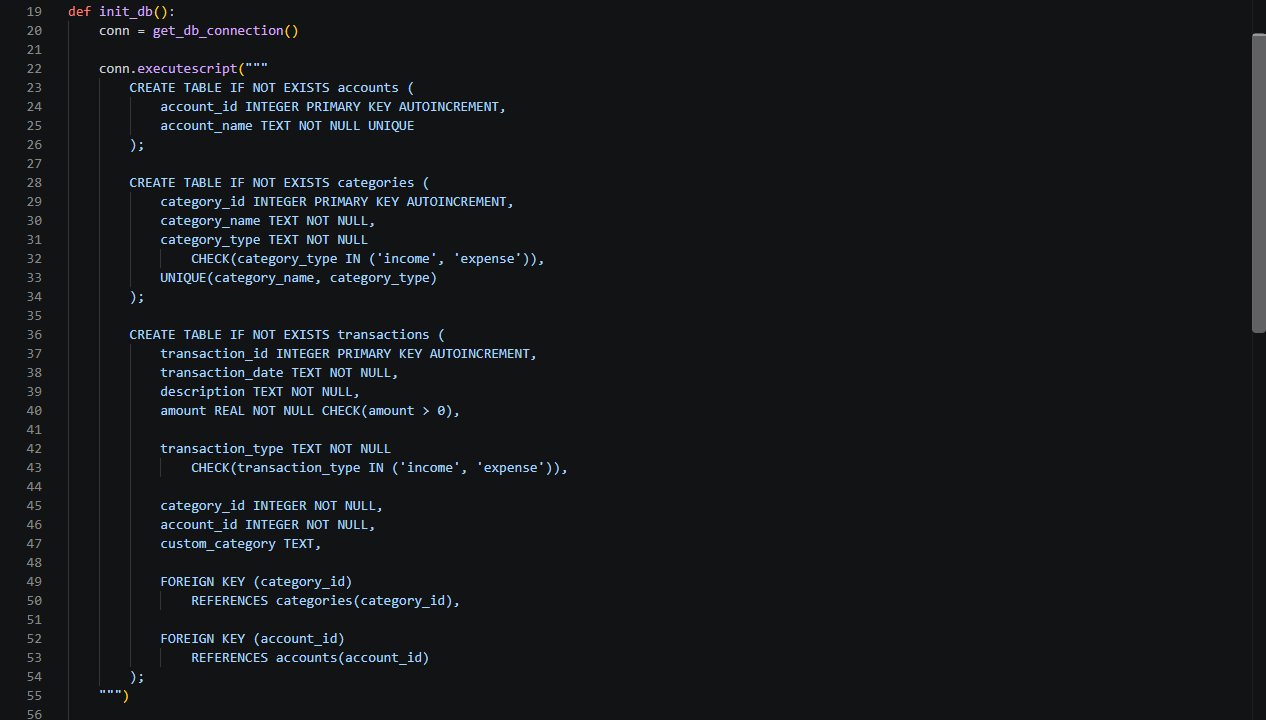

## 4.2 Transaction Entry

A transaction form was developed using Flask, HTML, CSS, and JavaScript.

Users can record income and expenses by specifying the transaction date, description, amount, transaction type, category, and account.

Input validation is included to ensure that transaction information is consistent before being stored in the database.

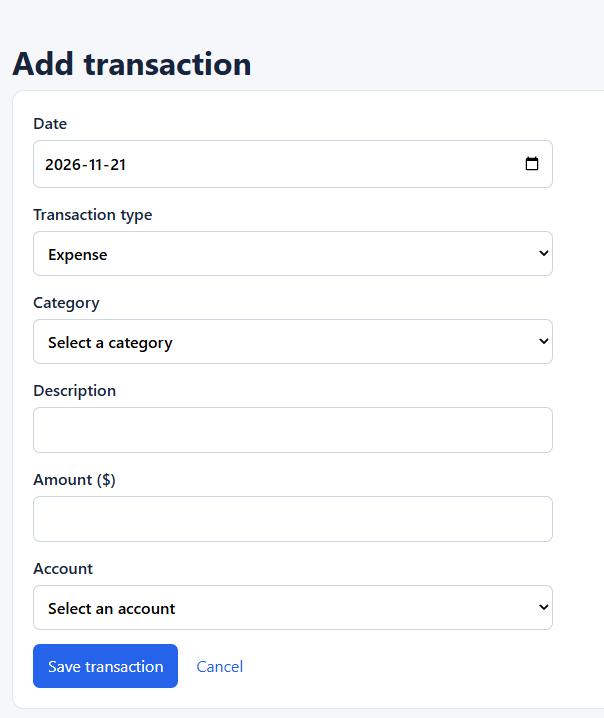

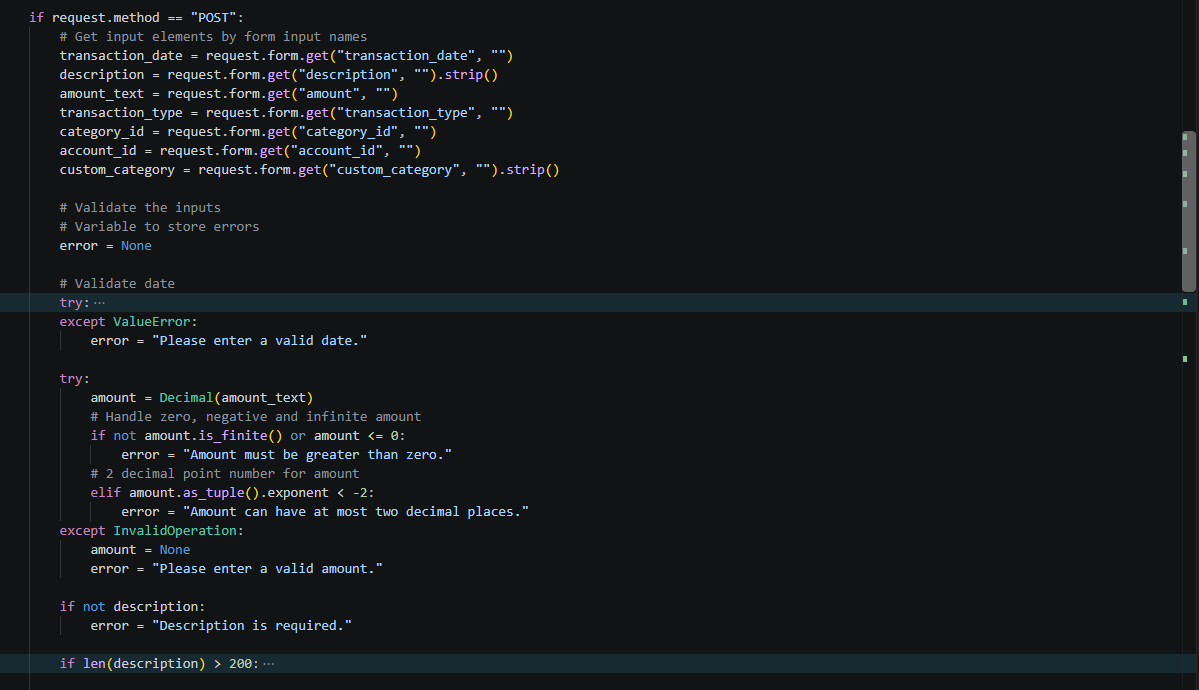

## 4.3 Transactions list
A transaction list web-page was created to list the recorded transactions and to manage them.

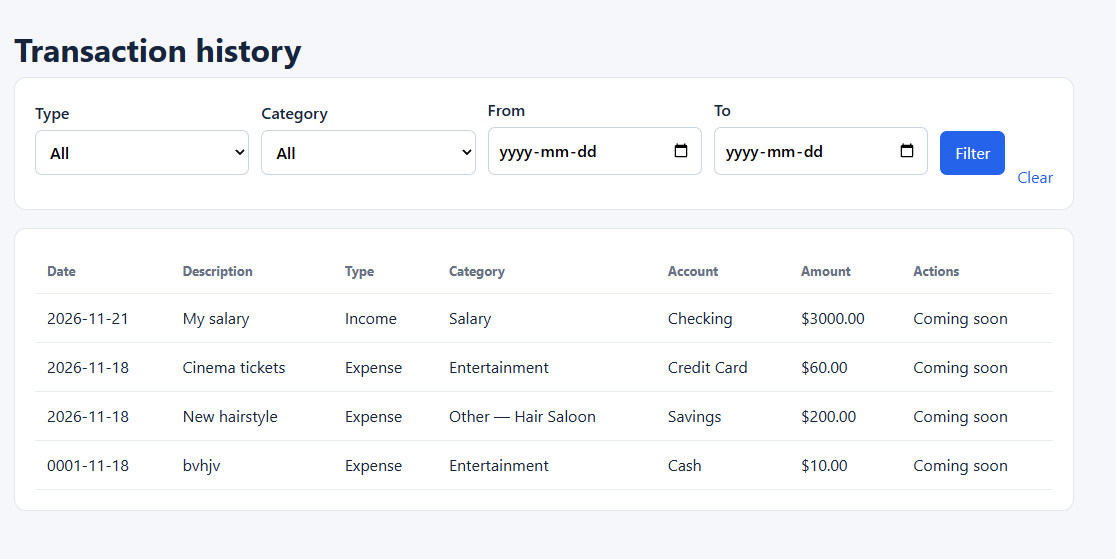

## 4.4 Category Management

Predefined income and expense categories were introduced to simplify transaction classification.

The available categories change dynamically depending on whether the user selects an income or expense transaction.

An additional text field is displayed when the user selects the "Other" category, allowing a custom category description.

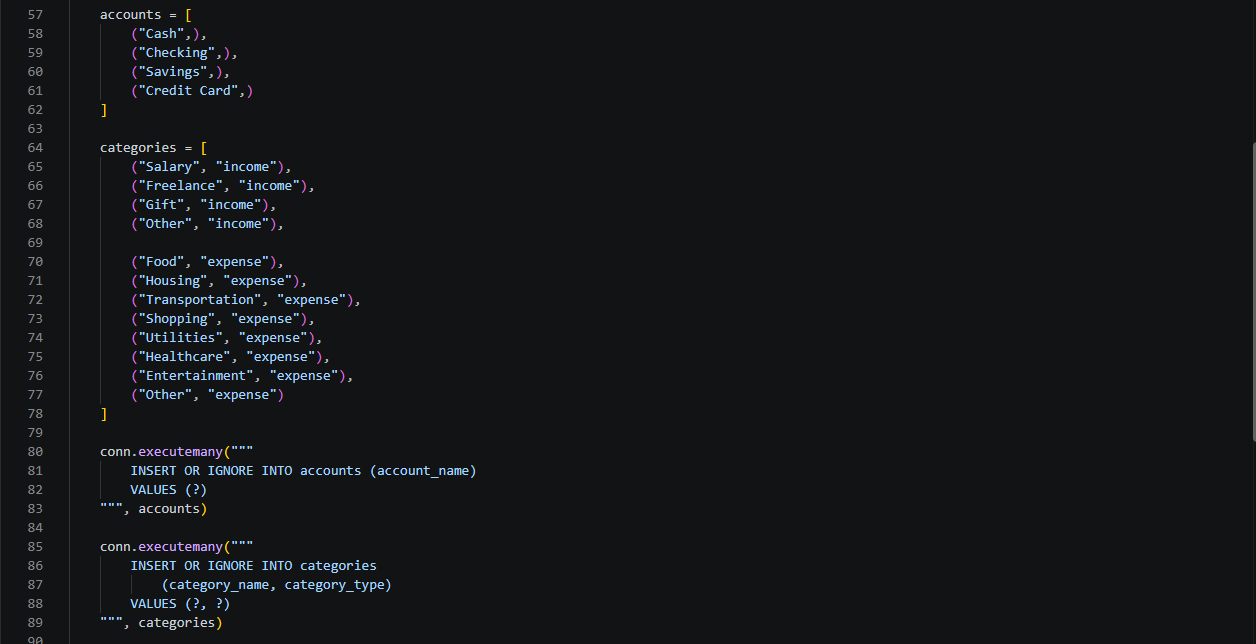

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from database import get_db_connection

Connection with the database

In [7]:
conn = get_db_connection()

In [8]:
query = """
SELECT
    t.transaction_date,
    t.description,
    t.amount,
    t.transaction_type,
    c.category_name,
    t.custom_category,
    a.account_name
FROM transactions t
JOIN categories c
    ON t.category_id = c.category_id
JOIN accounts a
    ON t.account_id = a.account_id
"""

Read and execute SQL query

In [9]:
df = pd.read_sql_query(query, conn)
conn.close()

In [10]:
df.head()

,transaction_date,description,amount,transaction_type,category_name,custom_category,account_name
0,2026-11-18,Cinema tickets,60.0,expense,Entertainment,NaN,Credit Card
1,2026-11-18,New hairstyle,200.0,expense,Other,Hair Saloon,Savings
2,0001-11-18,bvhjv,10.0,expense,Entertainment,NaN,Cash
3,2026-11-21,My salary,3000.0,income,Salary,NaN,Checking


In [11]:
expenses = df[df["transaction_type"] == "expense"]

In [12]:
expenses

,transaction_date,description,amount,transaction_type,category_name,custom_category,account_name
0,2026-11-18,Cinema tickets,60.0,expense,Entertainment,NaN,Credit Card
1,2026-11-18,New hairstyle,200.0,expense,Other,Hair Saloon,Savings
2,0001-11-18,bvhjv,10.0,expense,Entertainment,NaN,Cash


In [13]:
category_expenses=expenses.groupby("category_name")["amount"].sum()

In [14]:
category_expenses

category_name
Entertainment     70.0
Other            200.0
Name: amount, dtype: float64

In [15]:
category_expenses=category_expenses.sort_values(ascending=False)

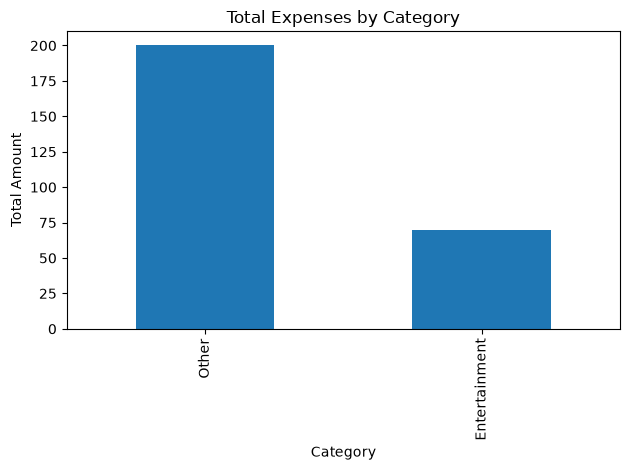

In [26]:
category_expenses.plot(kind="bar", title="Total Expenses by Category")
plt.xlabel("Category")
plt.ylabel("Total Amount")
plt.tight_layout()
plt.show()

In [19]:
df["transaction_date"] = pd.to_datetime(df["transaction_date"])

In [20]:
df['Month']=df['transaction_date'].dt.month_name()
df.head()

,transaction_date,description,amount,transaction_type,category_name,custom_category,account_name,Month
0,2026-11-18,Cinema tickets,60.0,expense,Entertainment,NaN,Credit Card,November
1,2026-11-18,New hairstyle,200.0,expense,Other,Hair Saloon,Savings,November
2,1-11-18,bvhjv,10.0,expense,Entertainment,NaN,Cash,November
3,2026-11-21,My salary,3000.0,income,Salary,NaN,Checking,November


In [22]:
monthly_summary = (
    df.groupby(["Month", "transaction_type"])["amount"]
    .sum()
)

In [24]:
monthly_summary

Month     transaction_type
November  expense              270.0
          income              3000.0
Name: amount, dtype: float64

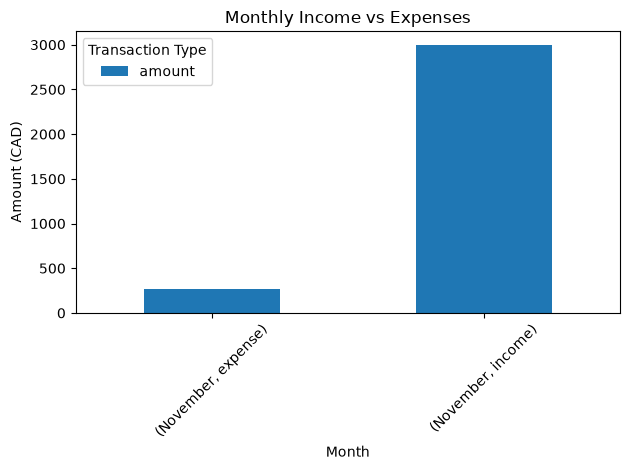

In [28]:
monthly_summary.plot(
    kind="bar",
    title="Monthly Income vs Expenses"
)

plt.xlabel("Month")
plt.ylabel("Amount (CAD)")
plt.xticks(rotation=45)
plt.legend(title="Transaction Type")
plt.tight_layout()
plt.show()

# Next Steps

- Transaction Management: Implement editing and deletion of existing transactions.

- Transaction Filtering: Allow users to filter transactions by date range, transaction type, category, and account.

- Receipt Upload and OCR: Allow users to upload receipt images and automatically extract transaction details, such as the date, amount, using Optical Character Recognition (OCR).

- Account Management: Enable users to manage accounts, set opening balances, and monitor available funds.

- Financial Dashboard: Integrate charts and additional financial summaries into the Flask dashboard.

- Financial Analysis: Introduce monthly spending trends, top expense categories, and comparisons between income and expenses.